<a href="https://colab.research.google.com/github/nahsiz/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day_17/day_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Required Libraries

Text Box Title: Importing Required Libraries

Text Box Description: Import Pandas, NumPy, Matplotlib, and Seaborn for data analysis and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset

Text Box Title: Loading the HR Employee Attrition Dataset

Text Box Description: Load the CSV file into a Pandas DataFrame and strip any extra whitespace from column names (including a BOM character at the start of the first column) so all column names work correctly.

In [2]:
data = pd.read_csv('/content/WA_Fn-UseC_-HR-Employee-Attrition.csv')
data.columns = data.columns.str.strip().str.replace('\ufeff', '', regex=False)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


3. Display First 5 Rows

Text Box Title: Displaying the First 5 Rows

Text Box Description: Use the head() function to quickly verify the dataset was loaded correctly.

In [3]:
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


4. Select Four Columns (Shared X-Axis)

Text Box Title: Selecting Four Columns for Correlation Analysis

Text Box Description: Select one shared x-axis column (Age) and three y-axis columns (MonthlyIncome, TotalWorkingYears, YearsAtCompany). Age will stay on the x-axis in all scatter plots so the three relationships can be compared against the same horizontal axis.

In [4]:
x_col = 'Age'
y_col_1 = 'MonthlyIncome'
y_col_2 = 'TotalWorkingYears'
y_col_3 = 'YearsAtCompany'

selected_data = data[[x_col, y_col_1, y_col_2, y_col_3]]

selected_data.head()

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany
0,41,5993,8,6
1,49,5130,10,10
2,37,2090,7,0
3,33,2909,8,8
4,27,3468,6,2


5. Calculate Pearson Correlation

Text Box Title: Calculating Correlation Between Four Columns

Text Box Description: Calculate the Pearson correlation coefficient three times — Age vs MonthlyIncome, Age vs TotalWorkingYears, and Age vs YearsAtCompany. Age remains the shared x-axis column in all three calculations.

In [5]:
correlation_1 = selected_data[x_col].corr(selected_data[y_col_1])
correlation_2 = selected_data[x_col].corr(selected_data[y_col_2])
correlation_3 = selected_data[x_col].corr(selected_data[y_col_3])

print("Correlation between", x_col, "and", y_col_1)
print("Pearson Correlation Coefficient:", round(correlation_1, 4))
print()
print("Correlation between", x_col, "and", y_col_2)
print("Pearson Correlation Coefficient:", round(correlation_2, 4))
print()
print("Correlation between", x_col, "and", y_col_3)
print("Pearson Correlation Coefficient:", round(correlation_3, 4))

Correlation between Age and MonthlyIncome
Pearson Correlation Coefficient: 0.4979

Correlation between Age and TotalWorkingYears
Pearson Correlation Coefficient: 0.6804

Correlation between Age and YearsAtCompany
Pearson Correlation Coefficient: 0.3113


6. Correlation Heatmap (4×4)

Text Box Title: Visualizing Correlation Using a Heatmap

Text Box Description: Create a 4×4 heatmap to display the correlation coefficients between all four selected columns at a glance.

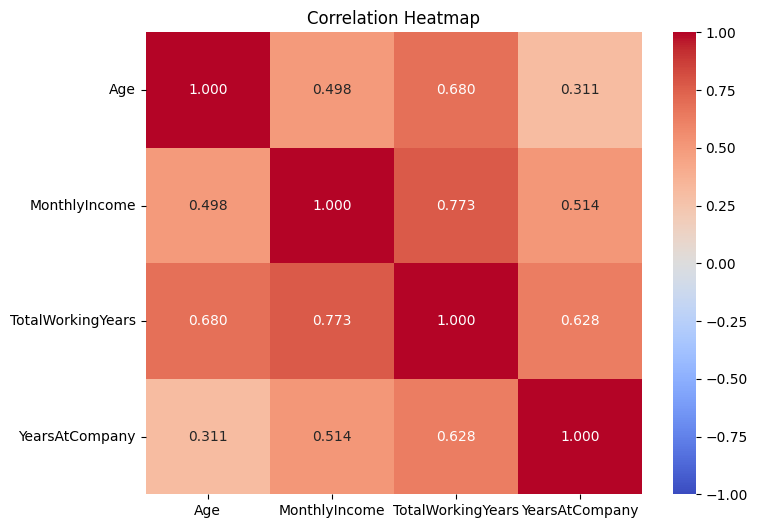

In [6]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    selected_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

7. Scatter Plot — Shared X with First Y

Text Box Title: Visualizing Age vs Monthly Income

Text Box Description: Create a scatter plot with a regression line where Age is on the x-axis and MonthlyIncome is on the y-axis. Age stays on the x-axis because it is the shared axis for all three plots.

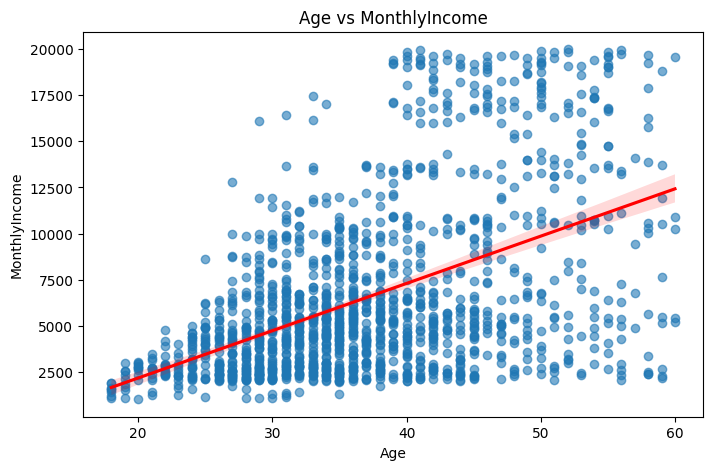

In [7]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_1,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_1}')
plt.xlabel(x_col)
plt.ylabel(y_col_1)
plt.show()

8. Scatter Plot — Shared X with Second Y

Text Box Title: Visualizing Age vs Total Working Years

Text Box Description: Create a scatter plot with a regression line where Age is again on the x-axis, but TotalWorkingYears is now on the y-axis. The x-axis stays identical to the previous plot so both relationships share the same horizontal axis.

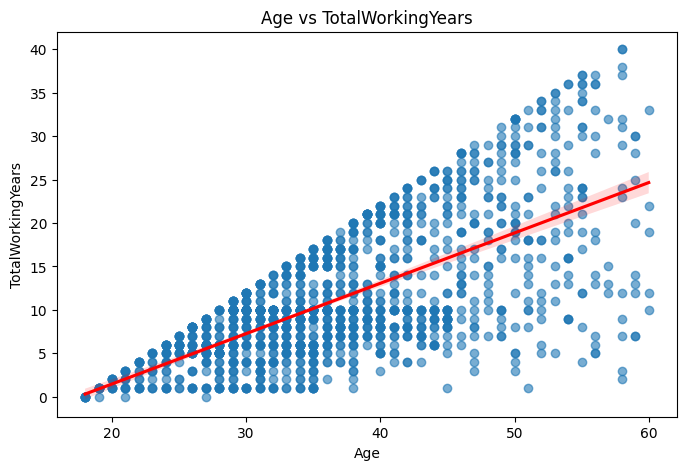

In [8]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_2}')
plt.xlabel(x_col)
plt.ylabel(y_col_2)
plt.show()

9. Scatter Plot — Shared X with Third Y

Text Box Title: Visualizing Age vs Years at Company

Text Box Description: Create a scatter plot with a regression line where Age is again on the x-axis, but YearsAtCompany is now on the y-axis. The x-axis stays identical so all three plots share the same horizontal axis.

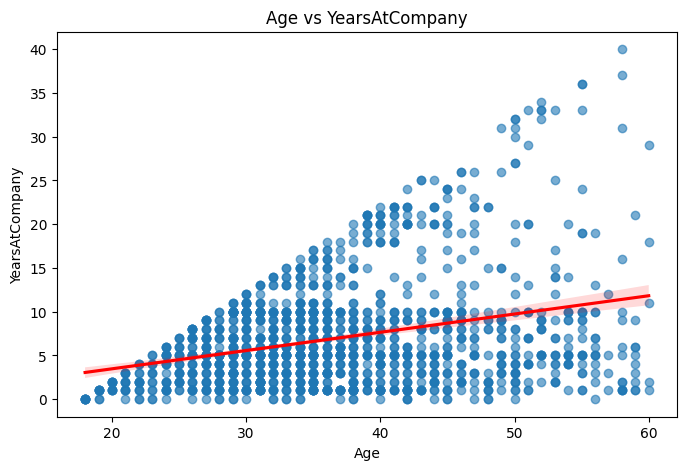

In [9]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_3,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_3}')
plt.xlabel(x_col)
plt.ylabel(y_col_3)
plt.show()

10. Interpret the First Correlation Result

Text Box Title: Interpreting the First Correlation Coefficient

Text Box Description: Identify whether the relationship between Age and MonthlyIncome is positive, negative, or has no linear correlation.

In [10]:
if correlation_1 > 0:
    print("Positive Correlation")
elif correlation_1 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_1, 4))

Positive Correlation
Correlation Value: 0.4979


11. Interpret the Second Correlation Result

Text Box Title: Interpreting the Second Correlation Coefficient

Text Box Description: Identify whether the relationship between Age and TotalWorkingYears is positive, negative, or has no linear correlation.

In [11]:
if correlation_2 > 0:
    print("Positive Correlation")
elif correlation_2 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_2, 4))

Positive Correlation
Correlation Value: 0.6804


12. Interpret the Third Correlation Result

Text Box Title: Interpreting the Third Correlation Coefficient

Text Box Description: Identify whether the relationship between Age and YearsAtCompany is positive, negative, or has no linear correlation.

In [12]:
if correlation_3 > 0:
    print("Positive Correlation")
elif correlation_3 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_3, 4))

Positive Correlation
Correlation Value: 0.3113


13. Display Final Correlation Result

Text Box Title: Final Correlation Analysis Result

Text Box Description: Display the shared x-axis column name and all three y-axis column names along with their calculated Pearson correlation coefficients.

In [13]:
print("Final Correlation Analysis")
print("--------------------------")

print("Shared X-Axis Column :", x_col)
print("First Y-Axis Column  :", y_col_1)
print("Pearson Correlation  :", round(correlation_1, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Second Y-Axis Column :", y_col_2)
print("Pearson Correlation  :", round(correlation_2, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Third Y-Axis Column  :", y_col_3)
print("Pearson Correlation  :", round(correlation_3, 4))

Final Correlation Analysis
--------------------------
Shared X-Axis Column : Age
First Y-Axis Column  : MonthlyIncome
Pearson Correlation  : 0.4979

Shared X-Axis Column : Age
Second Y-Axis Column : TotalWorkingYears
Pearson Correlation  : 0.6804

Shared X-Axis Column : Age
Third Y-Axis Column  : YearsAtCompany
Pearson Correlation  : 0.3113
